# Geometrie und Trigonometrie

## 05 - Das rechtwinklige Dreieck und der Satz des Pythagoras

Wir kommen nun zum wohl berühmtesten Lehrsatz der Mathematik. 

Jeder kennt die Formel $a^2 + b^2 = c^2$, aber in diesem Notebook wollen wir wirklich verstehen, *warum* sie gilt und wie wir sie nutzen können, um Distanzen zu berechnen, die wir nicht direkt messen können.

**Lernziele:**
- Du lernst die Begriffe **Kathete** und **Hypotenuse** sicher zu verwenden.
- Du verstehst den **geometrischen Beweis** des Satzes (Flächenvergleich).
- Du kannst fehlende Seitenlängen in rechtwinkligen Dreiecken berechnen.
- Du lernst die **Umkehrung** des Satzes kennen (Wie prüfe ich, ob ein Winkel $90°$ ist?).

### 1. Das rechtwinklige Dreieck

Bevor wir rechnen, müssen wir die Bauteile benennen. Der Satz des Pythagoras gilt **nur** in rechtwinkligen Dreiecken.

- **Der rechte Winkel ($90°$):** Er ist das markanteste Merkmal. Meist wird er mit einem Punkt in einem Viertelkreis markiert.
- **Die Hypotenuse:** Die längste Seite des Dreiecks. Sie liegt dem rechten Winkel immer **gegenüber**.
- **Die Katheten:** Die beiden kürzeren Seiten, die den rechten Winkel **einschließen** (sie "berühren" den rechten Winkel).

*Eselsbrücke:* Die **H**ypotenuse ist die **H**auptseite (die größte).

In [26]:
# Konfiguration für das Dreiecks-Plot
Dreieck_Config = {
    "a": 4,          # Kathete 1 (unten)
    "b": 3,          # Kathete 2 (links)
    "figsize": (6, 4),
    "color_hyp": "red",
    "color_cath": "blue"
}

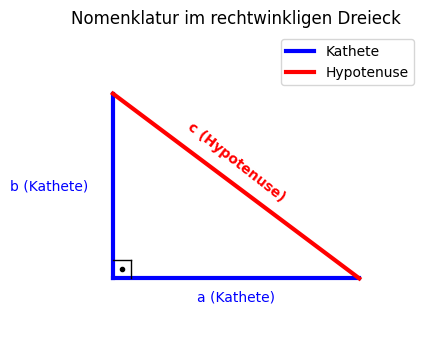

In [38]:
import matplotlib.pyplot as plt
import numpy as np

def plot_right_triangle(ax, cfg):
    a = cfg["a"]
    b = cfg["b"]
    
    # Koordinaten
    A = (0, b)
    B = (0, 0) # Der rechte Winkel
    C = (a, 0)
    
    # Dreieck zeichnen
    ax.plot([A[0], B[0]], [A[1], B[1]], color=cfg["color_cath"], lw=3, label='Kathete')
    ax.plot([B[0], C[0]], [B[1], C[1]], color=cfg["color_cath"], lw=3)
    ax.plot([C[0], A[0]], [C[1], A[1]], color=cfg["color_hyp"], lw=3, label='Hypotenuse')
    
    # Rechter Winkel Symbol
    box_size = min(a, b) * 0.1
    ax.plot([0, box_size], [box_size, box_size], 'k-', lw=1)
    ax.plot([box_size, box_size], [box_size, 0], 'k-', lw=1)
    ax.plot(box_size/2, box_size/2, 'k.') # Punkt
    
    # Beschriftung
    ax.text(-0.1 * a, b/2, 'b (Kathete)', va='center', ha='right', color=cfg["color_cath"])
    ax.text(a/2, -0.1 * b, 'a (Kathete)', va='center', ha='center', color=cfg["color_cath"])
    ax.text(a/2, b/2 - 0.3, 'c (Hypotenuse)', va='bottom', ha='center', color=cfg["color_hyp"], fontweight='bold', rotation=-38)
    
    # Setup
    ax.set_xlim(-1, a+1)
    ax.set_ylim(-1, b+1)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.legend(loc='upper right')
    ax.set_title("Nomenklatur im rechtwinkligen Dreieck")

fig, ax = plt.subplots(figsize=Dreieck_Config["figsize"])
plot_right_triangle(ax, Dreieck_Config)
plt.show()

### 2. Der Satz des Pythagoras

Das Theorem besagt:
**"In allen ebenen rechtwinkligen Dreiecken ist die Summe der Flächeninhalte der Kathetenquadrate gleich dem Flächeninhalt des Hypotenusenquadrats."**

$$a^2 + b^2 = c^2$$

Dabei sind $a$ und $b$ die Längen der Katheten und $c$ die Länge der Hypotenuse.

### 3. Der Beweis (Warum stimmt das?)

Es gibt hunderte Beweise für diesen Satz. Einer der anschaulichsten ist der **Umlegebeweis** (auch *Ergänzungsbeweis*).

**Die Idee:**
1. Wir nehmen zwei identische große Quadrate mit der Seitenlänge $(a+b)$.
2. **Links:** Wir füllen die Ecken mit vier gleichen Dreiecken. Es bleiben zwei Quadrate übrig ($a^2$ und $b^2$).
3. **Rechts:** Wir ordnen dieselben vier Dreiecke anders an. Es bleibt ein großes Quadrat in der Mitte übrig ($c^2$).
4. Da die Gesamtfläche gleich ist und wir gleich viel "Dreiecksfläche" abgezogen haben, muss der Rest auch gleich sein.

$$\text{Restfläche Links} = \text{Restfläche Rechts}$$
$$a^2 + b^2 = c^2$$

In [49]:
# Settings für den Beweis-Plot
Proof_Config = {
    "a": 3.0,
    "b": 4.0,
    "figsize": (12, 6),
    "color_a": "red",
    "color_b": "blue",
    "color_c": "purple",
    "color_tri": "orange",
    "alpha": 0.3
}

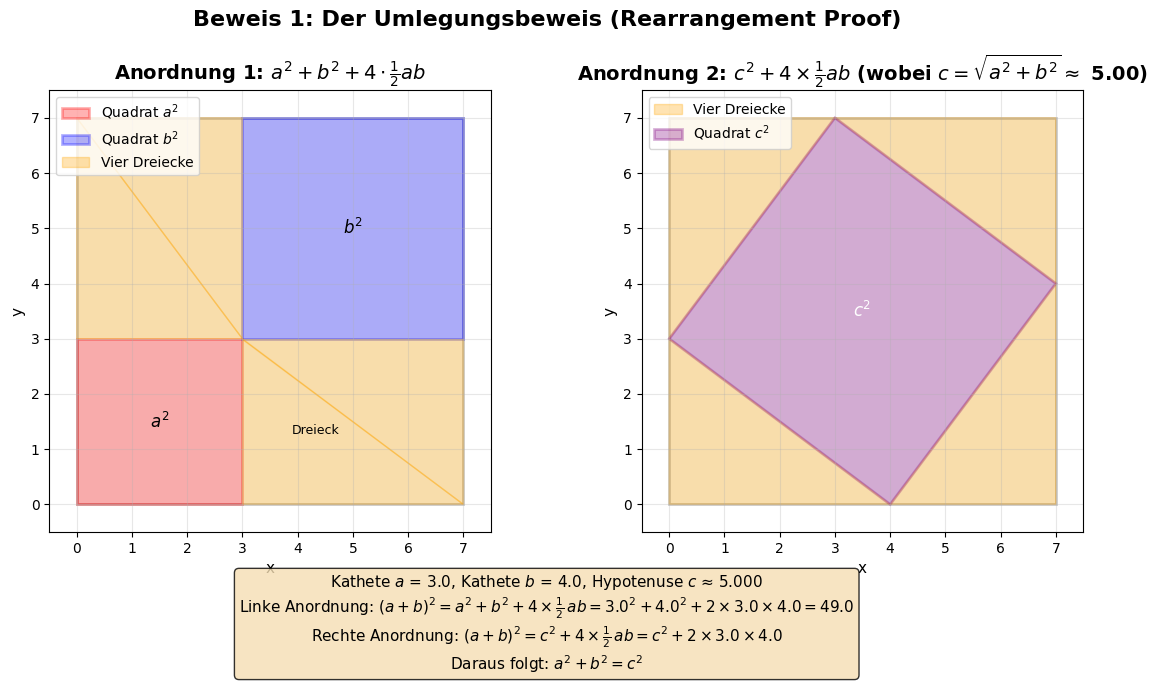

In [50]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# ================================================
# BEWEIS 1: UMLEGEBEWEIS (Rearrangement Proof)
# ================================================

def plot_rearrangement_proof(cfg):
    """
    Visualisiert den Umlegebeweis des Satzes des Pythagoras.

    Der Beweis zeigt, dass ein großes Quadrat mit Seitenlänge (a+b)
    auf zwei verschiedene Arten in kleiner Formen zerlegt werden kann,
    woarus a² + b² + c² folgt.

    Parameters:
    -----------
    a: float
        Länge der ersten Kathete
    b: float
        Länge der zweiten Kathete
    """
    a = cfg["a"]
    b = cfg["b"]
    figsize = cfg["figsize"]
    alpha = cfg["alpha"]
    color_a = cfg["color_a"]
    color_b = cfg["color_b"]
    color_c = cfg["color_c"]
    color_tri = cfg["color_tri"]

    c = np.sqrt(a**2 + b**2) # Hyptonuse nach Pythagoras

    # Eine Figur mit zwei Subplots erstellen 
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)

    # ================================================
    # LINKE SEITE: Zerlegung 1 (a² + b² + vier Dreiecke)
    # ================================================

    ax1.set_xlim(-0.5, a + b + 0.5)
    ax1.set_ylim(-0.5, a + b + 0.5)
    ax1.set_aspect('equal')
    ax1.set_title(r'Anordnung 1: $a^2 + b^2 + 4 \cdot \frac{1}{2}ab$', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=alpha)

    # Großes äußeres Quadrat (grau, transparent)
    outer_square1 = patches.Rectangle((0, 0), a + b, a + b, 
                                       linewidth=2, edgecolor='black', 
                                       facecolor='lightgray', alpha=0.2)
    ax1.add_patch(outer_square1)
    
    # Quadrat mit Seitenlänge a (unten links, rot)
    square_a = patches.Rectangle((0, 0), a, a, 
                                  linewidth=2, edgecolor=color_a, 
                                  facecolor=color_a, alpha=0.3, label=f'Quadrat $a^2$')
    ax1.add_patch(square_a)
    
    # Quadrat mit Seitenlänge b (oben rechts, blau)
    square_b = patches.Rectangle((a, a), b, b, 
                                  linewidth=2, edgecolor=color_b, 
                                  facecolor=color_b, alpha=0.3, label=f'Quadrat $b^2$')
    ax1.add_patch(square_b)
    
    # Vier rechtwinklige Dreiecke mit Katheten a und b
    # Dreieck 1: oberes linkes Rechteck, unten links
    triangle1 = patches.Polygon([(0, a), (a, a), (0, a + b)],
                                linewidth=1, edgecolor=color_tri,
                                facecolor=color_tri, alpha=0.3)

    # Dreieck 2: oberes linkes Rechteck, oben rechts
    triangle2 = patches.Polygon([(a, a), (0, a + b), (a, a + b)],
                                linewidth=1, edgecolor=color_tri,
                                facecolor=color_tri, alpha=0.3)

    # Dreieck 3: unteres rechtes Rechteck, unten links
    triangle3 = patches.Polygon([(a, 0), (a + b, 0), (a, a)],
                                linewidth=1, edgecolor=color_tri,
                                facecolor=color_tri, alpha=0.3)

    # Dreieck 4: unteres rechtes Rechteck, oben rechts
    triangle4 = patches.Polygon([(a + b, 0), (a + b, a), (a, a)],
                                linewidth=1, edgecolor=color_tri,
                                facecolor=color_tri, alpha=0.3,
                                label='Vier Dreiecke')

    ax1.add_patch(triangle1)
    ax1.add_patch(triangle2)
    ax1.add_patch(triangle3)
    ax1.add_patch(triangle4)
    
    # Beschriftungen für linke Seite
    ax1.text(a/2, a/2, f'$a^2$', fontsize=12, ha='center', va='center', fontweight='bold')
    ax1.text(a + b/2, a + b/2, f'$b^2$', fontsize=12, ha='center', va='center', fontweight='bold')
    ax1.text(a + b/3, b/3, f'Dreieck', fontsize=9, ha='center', va='center')
    
    ax1.set_xlabel('x', fontsize=11)
    ax1.set_ylabel('y', fontsize=11)
    ax1.legend(loc='upper left', fontsize=10)
    
    # ========================================================================
    # RECHTE SEITE: Zerlegung 2 (c² + vier Dreiecke)
    # ========================================================================
    
    ax2.set_xlim(-0.5, a + b + 0.5)
    ax2.set_ylim(-0.5, a + b + 0.5)
    ax2.set_aspect('equal')
    ax2.set_title(r'Anordnung 2: $c^2 + 4 \times \frac{{1}}{{2}}ab$ (wobei $c = \sqrt{{a^2 + b^2}} \approx$' + f' {c:.2f})', 
                  fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    
    # Großes äußeres Quadrat (grau, transparent)
    outer_square2 = patches.Rectangle((0, 0), a + b, a + b, 
                                       linewidth=2, edgecolor='black', 
                                       facecolor='lightgray', alpha=0.2)
    ax2.add_patch(outer_square2)
    
    # Vier rechtwinklige Dreiecke (rotiert um das zentrale Quadrat)
    # Diese Dreiecke werden mit ihren Hypotenusen nach außen angeordnet
    
    # Dreieck unten links
    t1_coords = [(0, 0),      # Ecke des großen Quadrats
                 (0, a),      # nach oben: Länge a
                 (b, 0)]      # nach rechts: Länge b
    
    triangle_1 = patches.Polygon(t1_coords,
                                 linewidth=1,
                                 edgecolor=color_tri,
                                 facecolor=color_tri,
                                 alpha=alpha)
    ax2.add_patch(triangle_1)
    
    # Dreieck unten rechts
    t2_coords = [(a + b, 0),
                 (b, 0),
                 (a + b, b)]
    
    triangle_2 = patches.Polygon(t2_coords,
                                 linewidth=1,
                                 edgecolor=color_tri,
                                 facecolor=color_tri,
                                 alpha=alpha)
    ax2.add_patch(triangle_2)
    
    # Dreieck oben rechts
    t3_coords = [(a + b, a + b),
                 (a + b, b),
                 (a, a + b)]
    
    triangle_3 = patches.Polygon(t3_coords,
                                 linewidth=1,
                                 edgecolor=color_tri,
                                 facecolor=color_tri,
                                 alpha=alpha)
    ax2.add_patch(triangle_3)
    
    # Dreieck oben links
    t4_coords = [(0, a + b),
                 (a, a + b),
                 (0, a)]
    
    triangle_4 = patches.Polygon(t4_coords,
                                 linewidth=1,
                                 edgecolor=color_tri,
                                 facecolor=color_tri,
                                 alpha=alpha,
                                 label='Vier Dreiecke')
    ax2.add_patch(triangle_4)

    
    # Zentrales Quadrat mit Seitenlänge c (rotiert um 45°)
    # Das Quadrat über der Hypotenuse
    center_x = (a + b) / 2
    center_y = (a + b) / 2
    
    # Eckpunkte des rotierten Quadrates
    angle = np.arctan(a / b)  # Rotationswinkel basierend auf dem Dreieck
    
    # Berechne die Eckpunkte des Quadrats in der Mitte
    p1 = (b, 0)
    p2 = (a + b, b)
    p3 = (a, a + b)
    p4 = (0, a)
    
    inner_square = patches.Polygon([p1, p2, p3, p4],
                                   linewidth=2,
                                   edgecolor=color_c,
                                   facecolor=color_c,
                                   alpha=alpha,
                                   label=r'Quadrat $c^2$')
    ax2.add_patch(inner_square)
    
    # Beschriftung für c²
    ax2.text(center_x, center_y, f'$c^2$', fontsize=12, ha='center', va='center', 
             fontweight='bold', color='white')
    
    ax2.set_xlabel('x', fontsize=11)
    ax2.set_ylabel('y', fontsize=11)
    ax2.legend(loc='upper left', fontsize=10)
    
    # Gesamttitel
    fig.suptitle('Beweis 1: Der Umlegungsbeweis (Rearrangement Proof)', 
                 fontsize=16, fontweight='bold', y=1.02)
    
    # Erklärung hinzufügen
    explanation = (
        f'Kathete $a$ = {a}, Kathete $b$ = {b}, Hypotenuse $c$ ≈ {c:.3f}\n'
        f'Linke Anordnung: $(a+b)^2 = a^2 + b^2 + 4 \\times \\frac{{1}}{{2}} \\, ab = {a}^2 + {b}^2 + 2 \\times {a} \\times {b} = {(a+b)**2}$\n'
        f'Rechte Anordnung: $(a+b)^2 = c^2 + 4 \\times \\frac{{1}}{{2}} \\, ab = c^2 + 2 \\times {a} \\times {b}$\n'
        f'Daraus folgt: $a^2 + b^2 = c^2$'
    )
    fig.text(0.5, -0.08, explanation, ha='center', fontsize=11, 
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.15)
    
    return fig, ax1, ax2

# Visualisierung ausführen
fig, ax1, ax2 = plot_rearrangement_proof(Proof_Config)
plt.show()    

    

### 5. Rechnen mit Pythagoras

Der Satz $a^2 + b^2 = c^2$ ist eine Gleichung. Wenn wir zwei Seiten kennen, können wir die dritte immer ausrechnen.

**Fall A: Hypotenuse gesucht**
Gegeben: Katheten $a=3, b=4$. Gesucht: $c$.
$$c^2 = 3^2 + 4^2 = 9 + 16 = 25$$
$$c = \sqrt{25} = 5$$

**Fall B: Kathete gesucht**
Gegeben: Hypotenuse $c=10$, Kathete $a=8$. Gesucht: $b$.
Wir stellen die Formel um: $b^2 = c^2 - a^2$.
$$b^2 = 10^2 - 8^2 = 100 - 64 = 36$$
$$b = \sqrt{36} = 6$$

### 6. Pythagoreische Tripel

Im Beispiel oben (3, 4, 5) kommen glatte ganze Zahlen heraus, das ist selten! Meistens ergeben Wurzeln "krumme" Kommazahlen (Irrationale Zahlen).
Ganzzahlige Lösungen nennt man **Pythagoreische Tripel**.
Die wichtigsten zum Auswendiglernen:
- $(3, 4, 5)$
- $(5, 12, 13)$
- $(8, 15, 17)$

### 7. Die Umkehrung des Satzes

Der Satz gilt auch rückwärts:
**"Wenn in einem Dreieck die Summe der Quadrate zweier Seiten gleich dem Quadrat der dritten Seite ist, dann ist das Dreieck rechtwinklig."**

Das ist extrem nützlich für Handwerker (z.B. die "Zimmerer-Methode" oder "3-4-5-Methode" um rechte Winkel auf Baustellen abzustecken).

---

### Übungsaufgaben

**Aufgabe 1: Die Leiter**
Eine 5 Meter lange Leiter lehnt an einer Hauswand. Der Fuß der Leiter steht 3 Meter von der Wand entfernt.
Wie hoch reicht die Leiter? (Skizziere ein Dreieck: Leiter = Hypotenuse).

**Aufgabe 2: Der Bildschirm**
Ein Fernseher wird als "50 Zoll" verkauft. Das ist die Länge der Diagonalen. Der Bildschirm ist 40 Zoll breit.
Wie hoch ist der Bildschirm?

**Aufgabe 3: Rechtwinklig oder nicht?**
Ein Dreieck hat die Seitenlängen 6 cm, 7 cm und 9 cm. Ist es rechtwinklig?

### Lösungen

**Lösung 1:**
Gegeben: $c=5$ (Leiter), $a=3$ (Abstand). Gesucht: $b$ (Höhe).
$$b^2 = c^2 - a^2 = 5^2 - 3^2 = 25 - 9 = 16$$
$$b = \sqrt{16} = 4$$
Die Leiter reicht **4 Meter** hoch.

**Lösung 2:**
Gegeben: $c=50$ (Diagonale), $a=40$ (Breite). Gesucht: $b$ (Höhe).
$$b^2 = 50^2 - 40^2 = 2500 - 1600 = 900$$
$$b = \sqrt{900} = 30$$
Der Bildschirm ist **30 Zoll** hoch. (Dies ist ein 3:4:5 Tripel, multipliziert mit 10).

**Lösung 3:**
Wir prüfen, ob $a^2 + b^2 = c^2$ gilt. Die längste Seite (9) muss $c$ sein.
$$6^2 + 7^2 = 36 + 49 = 85$$
$$c^2 = 9^2 = 81$$
Da $85 \neq 81$, ist das Dreieck **nicht rechtwinklig**.

---
### Glossar (Deutsch - Englisch)

- **Rechtwinkliges Dreieck:** Right-angled triangle
- **Kathete:** Cathetus (plural: Catheti) / Leg
- **Hypotenuse:** Hypotenuse
- **Satz des Pythagoras:** Pythagorean theorem
- **Wurzel:** Square root
- **Quadrat:** Square
- **Fläche:** Area
- **Umkehrung:** Converse